# Descenso de Wirtinger con Adam frente a Gerchberg-Saxton con iguales iteraciones

**Pregunta:** ¿Un método de gradiente que no sabe nada de Gerchberg-Saxton, el descenso de Wirtinger con Adam (M11), alcanza la uniformidad de los lazos de proyección en la tarea de 10 x 10 trampas con iguales iteraciones?

- Nivel: 3, estado del arte. Método ejecutado: M11.
- Requisitos previos: `05-optimization/02-the-wirtinger-gradient-and-adams-step`, que deriva el gradiente y fija la tasa de aprendizaje.
- Tiempo de lectura: unos 25 minutos. El notebook se ejecuta en cerca de un minuto y medio.

## Objetivos

Un notebook de nivel 3 ejecuta un método del estado del arte sobre los datos del producto y lo mide frente a lo anterior. M11 viene de la holografía de aprendizaje automático (Chakravarthula et al., 2019): su atractivo es que no necesita una regla escrita para el problema, solo un modelo diferenciable y una pérdida. El precio se paga en iteraciones, y este notebook las cuenta. Al terminar puedes:

- comparar M11 con Gerchberg-Saxton simple y ponderado en tres semillas con el presupuesto del registro de 30 iteraciones;
- decir qué dice la dispersión de las tres semillas sobre cada método;
- seguir los tres métodos hasta 100 iteraciones y leer tanto las curvas como las intensidades finales de las trampas;
- decir qué afirmación de la escalera de métodos respaldan los números, y cuál no.

## Preparación


El entorno de notebooks está fijado en `notebooks/requirements.txt` y se construye con `scripts/setup.sh --notebooks`
(`scripts/setup.ps1 -Notebooks` en Windows). Este notebook usa dos paquetes, con estas versiones exactas:

```bash
pip install numpy==2.4.6 matplotlib==3.11.2
```

DinHot no publica un paquete propio: sus métodos viven en la carpeta del pipeline `data-pipeline/`, y la celda siguiente
pone esa carpeta en la ruta de importación e importa las funciones que el notebook llama.

In [1]:
# las herramientas, sus versiones y la carpeta del pipeline en la ruta de importación
import sys
from importlib.metadata import version
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np

ROOT = Path("../../..").resolve()
sys.path.insert(0, str(ROOT / "data-pipeline"))
from pipeline.cases import build
from pipeline.io.contract import read_cases
from pipeline.model.holo.core.device import Device
from pipeline.model.holo.core.rng import Rng
from pipeline.model.holo.core.types import Budget
from pipeline.model.holo.methods.baseline import m04_gs, m06_gsw
from pipeline.model.holo.methods.optim import m11_wirtinger_adam
from pipeline.model.holo.methods.optim.costs import TrapCost

print("numpy", version("numpy"), "| matplotlib", version("matplotlib"))

numpy 2.4.6 | matplotlib 3.11.2


## Datos

El notebook lee el caso C12 de `data/examples/cases.json`, la misma tarea de calibración de 10 x 10 del notebook anterior.

- Propietario: este repositorio; el caso es sintético y sigue la tarea de Di Leonardo, Ianni y Ruocco (2007).
- Clase de licencia: datos generados bajo la licencia del propio repositorio, sin conjuntos de datos de terceros.
- Archivo: `data/examples/cases.json`, caso C12.

In [2]:
# caso C12: el montaje óptico y las 100 trampas de la tarea de 10 x 10
rec = {c["case_id"][:3]: c for c in read_cases(ROOT / "data/examples/cases.json")}["C12"]
setup = build.setup_of(rec)
target = build.target_of(rec)
n = setup.n_pix
print(rec["case_id"], "|", len(target.traps), "trampas | SLM", n, "x", n, "píxeles")

C12_calibration | 100 trampas | SLM 256 x 256 píxeles


## Método

M11 minimiza la pérdida cuadrática $C_2$ del tema de optimización con Adam sobre el gradiente de Wirtinger, con la tasa de aprendizaje 1,0 ajustada en el notebook anterior, partiendo de fases aleatorias sorteadas con el generador con semilla. No tiene pesos, ni fijación de fase, ni proyección. Los dos métodos con que se compara son los lazos clásicos de Di Leonardo et al. (2007): M04, Gerchberg-Saxton simple, que reemplaza la amplitud en el plano focal por el objetivo y no tiene mecanismo que iguale las trampas, y M06, el lazo ponderado, que multiplica el objetivo de cada trampa por un peso que corrige su déficit. La escalera de métodos le pide a M11 un error de intensidad en las trampas menor que el de M04 con iguales iteraciones, así que M04 es el contrato; M06 es el oponente clásico más fuerte.

## Estado del arte

No existe una implementación de referencia fijada de M11 entre las dependencias del notebook (slmsuite ofrece la familia de Gerchberg-Saxton, no el descenso de gradiente a través de un modelo diferenciable), así que el estado del arte se ejecuta como el M11 propio de DinHot frente a sus propios lazos clásicos en la misma tarea, las mismas tres semillas y el mismo presupuesto. La primera celda ejecuta M04 durante 30 iteraciones en tres semillas.

In [3]:
# Gerchberg-Saxton simple, M04, 30 iteraciones en tres semillas
spread = {"M04 GS": [], "M06 GSW": [], "M11 Adam": []}
for seed in (1, 2, 3):
    spread["M04 GS"].append(m04_gs.run(setup, target, budget=Budget(30), rng=Rng(seed)).history[-1]["rel_std"])
print(f"M04: desv. rel. por semilla {np.round(spread['M04 GS'], 2)} %  media {np.mean(spread['M04 GS']):.2f} %")

M04: desv. rel. por semilla [17.28 18.38 18.76] %  media 18.14 %


Gerchberg-Saxton simple deja las trampas entre 17,28 y 18,76 por ciento separadas. El lazo ponderado M06 es la respuesta clásica a eso, y la segunda celda lo ejecuta en las mismas semillas.

In [4]:
# GS ponderado, M06, la referencia clásica, con el mismo presupuesto y semillas
for seed in (1, 2, 3):
    spread["M06 GSW"].append(m06_gsw.run(setup, target, budget=Budget(30), rng=Rng(seed)).history[-1]["rel_std"])
print(f"M06: desv. rel. por semilla {np.round(spread['M06 GSW'], 2)} %  media {np.mean(spread['M06 GSW']):.2f} %")

M06: desv. rel. por semilla [0.92 1.85 0.98] %  media 1.25 %


M06 está en 0,92, 1,85 y 0,98 por ciento. La tercera celda ejecuta M11 con el mismo presupuesto y semillas.

In [5]:
# Wirtinger-Adam, M11, tasa de aprendizaje 1.0, el mismo presupuesto y semillas
for seed in (1, 2, 3):
    res = m11_wirtinger_adam.run(setup, target, budget=Budget(30), rng=Rng(seed))
    spread["M11 Adam"].append(res.history[-1]["rel_std"])
print(f"M11: desv. rel. por semilla {np.round(spread['M11 Adam'], 2)} %  media {np.mean(spread['M11 Adam']):.2f} %")

M11: desv. rel. por semilla [2.56 2.66 2.22] %  media 2.48 %


Las barras grafican la desviación estándar relativa de cada método en cada semilla, en un eje logarítmico.

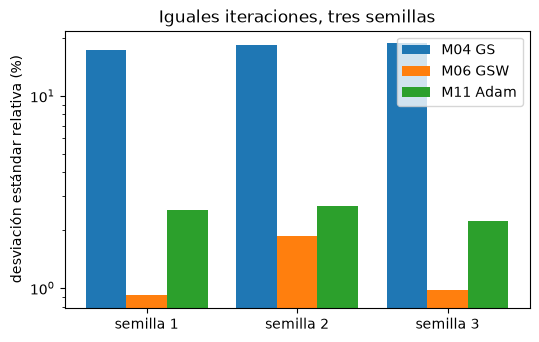

In [6]:
# desviación estándar relativa de los tres métodos en cada semilla, 30 iteraciones
fig, ax = plt.subplots(figsize=(6.0, 3.6))
for k, (name, values) in enumerate(spread.items()):
    ax.bar(np.arange(3) + 0.27 * (k - 1), values, 0.27, label=name)
ax.set_xticks(range(3))
ax.set_xticklabels(["semilla 1", "semilla 2", "semilla 3"])
ax.set_ylabel("desviación estándar relativa (%)")
ax.set_title("Iguales iteraciones, tres semillas")
ax.set_yscale("log")
ax.legend()
plt.show()

M11 supera a Gerchberg-Saxton simple en cada semilla, con una media de 2,48 por ciento frente a 18,14, un factor de 7 que es el mismo en las tres, de modo que el criterio de la escalera de métodos se cumple y no depende de la semilla. No supera al lazo ponderado, cuya media es 1,25 por ciento. Las semillas muestran además una diferencia de carácter: M06 va de 0,92 a 1,85 por ciento, un factor de 2, porque su actualización de pesos tiene la sensibilidad al inicio que tiene el camino de un lazo adaptativo, mientras M11 va solo de 2,22 a 2,66, un factor de 1,2, ya que un descenso sobre un costo suave olvida su inicio antes. La figura es para 30 iteraciones; las celdas siguientes siguen a los tres métodos más lejos.

Treinta iteraciones es el valor por defecto del registro, pero un método de descenso también se juzga por adónde llega con más. Las tres celdas siguientes ejecutan los tres métodos durante 100 iteraciones en la semilla 1, y conservan el campo final para poder comparar la intensidad de cada trampa. Primero M04.

In [7]:
# los mismos tres métodos con 100 iteraciones en la semilla 1: primero M04
long = {"M04 GS": m04_gs.run(setup, target, budget=Budget(100), rng=Rng(1))}
h30, h100 = long["M04 GS"].history[29], long["M04 GS"].history[99]
print(f"M04: desv. rel. a las 30 y 100 iteraciones {h30['rel_std']:.2f} % {h100['rel_std']:.2f} %  "
      f"eficiencia {h100['efficiency']:.3f}")

M04: desv. rel. a las 30 y 100 iteraciones 17.28 % 16.46 %  eficiencia 0.819


M04 se ha estancado: su dispersión es 17,28 por ciento a las 30 iteraciones y 16,46 a las 100. Luego M06.

In [8]:
# luego M06
long["M06 GSW"] = m06_gsw.run(setup, target, budget=Budget(100), rng=Rng(1))
h30, h100 = long["M06 GSW"].history[29], long["M06 GSW"].history[99]
print(f"M06: desv. rel. a las 30 y 100 iteraciones {h30['rel_std']:.2f} % {h100['rel_std']:.2f} %  "
      f"eficiencia {h100['efficiency']:.3f}")

M06: desv. rel. a las 30 y 100 iteraciones 0.92 % 0.24 %  eficiencia 0.807


M06 pasa de 0,92 a 0,24 por ciento. Y M11.

In [9]:
# y M11
long["M11 Adam"] = m11_wirtinger_adam.run(setup, target, budget=Budget(100), rng=Rng(1))
h30, h100 = long["M11 Adam"].history[29], long["M11 Adam"].history[99]
print(f"M11: desv. rel. a las 30 y 100 iteraciones {h30['rel_std']:.2f} % {h100['rel_std']:.2f} %  "
      f"eficiencia {h100['efficiency']:.3f}")

M11: desv. rel. a las 30 y 100 iteraciones 2.56 % 1.15 %  eficiencia 0.808


El panel izquierdo grafica la dispersión frente a la iteración y el derecho las intensidades ordenadas de las trampas.

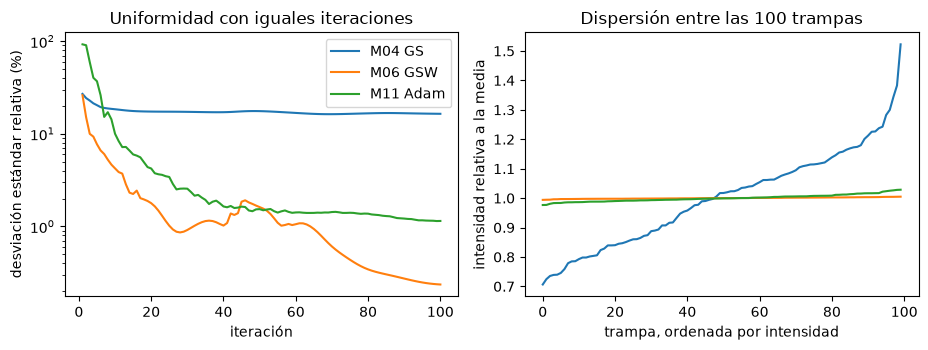

In [10]:
# izquierda: dispersión relativa por iteración; derecha: intensidades ordenadas tras 100 iteraciones
fig, (a, b) = plt.subplots(1, 2, figsize=(9.4, 3.6))
for name, res in long.items():
    a.semilogy([h["iteration"] for h in res.history], [h["rel_std"] for h in res.history], label=name)
    inten = np.abs(res.fields) ** 2
    b.plot(np.sort(inten / inten.mean()), label=name)
a.set_xlabel("iteración")
a.set_ylabel("desviación estándar relativa (%)")
a.set_title("Uniformidad con iguales iteraciones")
a.legend()
b.set_xlabel("trampa, ordenada por intensidad")
b.set_ylabel("intensidad relativa a la media")
b.set_title("Dispersión entre las 100 trampas")
plt.tight_layout()
plt.show()

A la izquierda, Gerchberg-Saxton simple se estanca cerca de 17 por ciento: no tiene un mecanismo que iguale las trampas, y su punto fijo es desigual por construcción. M11 baja de forma sostenida y, a las 100 iteraciones, está en 1,15 por ciento; el lazo ponderado M06 está aún más abajo, en 0,24 por ciento, con un valle y una joroba en el camino que vienen de su actualización de pesos. A la derecha, las intensidades ordenadas dicen dónde vive la dispersión. M04 tiene una cola larga de trampas débiles, las más débiles con cerca de 0,7 de la media y las más fuertes con 1,5 veces; M11 y M06 son planas, y las dos curvas no se distinguen a esta escala. El gráfico respalda una afirmación acotada: un gradiente a través del modelo directo supera a una proyección sin pesos y se acerca a una con pesos, sin pesos, y sin saber nada de Gerchberg-Saxton. No muestra que M11 supere a M06, y no lo hace.

## Resultados

**Respuesta:** M11 alcanza la uniformidad de los lazos de proyección solo en parte. Con iguales iteraciones supera a Gerchberg-Saxton simple en cada semilla, con una desviación estándar relativa media de 2,48 por ciento frente a 18,14 de M04 a las 30 iteraciones, y está en 1,15 por ciento tras 100 iteraciones frente a 16,46 de M04. No iguala al lazo ponderado, que tiene una media de 1,25 por ciento a las 30 iteraciones y está en 0,24 por ciento tras 100, con M11 repartido en un rango más angosto entre semillas (2,22 a 2,66 por ciento frente a 0,92 a 1,85). Así que el criterio de aceptación de la escalera de métodos se cumple y M11 es un método del estado del arte que no necesita una regla escrita para el problema, pero en una tarea simple de trampas puntuales el lazo ponderado clásico es la mejor herramienta.

Lo que el notebook no muestra es una implementación independiente de M11, que no existe entre las dependencias, ni los objetivos donde no hay regla de pesos y la generalidad es el punto.

## Resumen

- M11 supera a Gerchberg-Saxton simple en cada semilla a las 30 iteraciones, por un factor de 7 en la dispersión media.
- El lazo ponderado M06 sigue adelante en esta tarea a las 30 y a las 100 iteraciones.
- M11 varía menos entre semillas que M06.
- No existe una implementación de referencia fijada de M11 entre las dependencias, así que el estado del arte es el método propio de DinHot frente a sus propios lazos clásicos.

## Referencias

- Chakravarthula et al. (2019). Wirtinger holography for near-eye displays. ACM Transactions on Graphics 38, 213. https://doi.org/10.1145/3355089.3356539
- Schroff et al. (2023). Accurate holographic light potentials using pixel crosstalk modelling. Scientific Reports 13, 3252. https://doi.org/10.1038/s41598-023-30296-6
- Di Leonardo, Ianni and Ruocco (2007). Computer generation of optimal holograms for optical trap arrays. Optics Express 15, 1913. https://doi.org/10.1364/OE.15.001913
- Kingma and Ba (2015). Adam: a method for stochastic optimization. https://arxiv.org/abs/1412.6980